# 🛍️ Customer Segmentation — RFM + K-Means Clustering

**Author:** Rihab Douhab  
**Dataset:** Online Retail II (UCI Machine Learning Repository)  
**Stack:** Python · Pandas · scikit-learn · Matplotlib · Seaborn

---

## 🎯 Objective

Segment customers into meaningful groups based on purchasing behaviour using the **RFM framework** and **K-Means clustering**.

| Metric | Description |
|--------|-------------|
| **Recency (R)** | Days since the customer's last purchase |
| **Frequency (F)** | Number of distinct orders placed |
| **Monetary (M)** | Total amount spent |

---

## 📋 Methodology

1. **Data Cleaning** — handle nulls, cancellations, negative values  
2. **RFM Calculation** — one row per customer  
3. **Normalisation** — log-transform + StandardScaler  
4. **Optimal k** — Elbow method + Silhouette score  
5. **K-Means Training** — fit & label clusters  
6. **Visualisation** — snake plot, heatmap, PCA scatter, pie chart  
7. **Recommendations** — per-segment marketing actions  


## 📦 0. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import os

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.family"] = "DejaVu Sans"
PALETTE = ["#6C63FF", "#F7931E", "#2EC4B6", "#E71D36", "#011627"]

print("✅ Imports OK")

✅ Imports OK


## 📂 1. Load Data

In [2]:
DATA_PATH = "../data/online_retail_II.xlsx"

print("📂 Loading dataset (this may take ~30 seconds)…")
df = pd.read_excel(DATA_PATH, sheet_name="Year 2010-2011", engine="openpyxl")
print(f"Shape: {df.shape}")
print(df.head())
print(df.dtypes)
print(df.isnull().sum())

📂 Loading dataset (this may take ~30 seconds)…


Shape: (541910, 8)
  Invoice StockCode                          Description  Quantity  \
0  536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1  536365     71053                  WHITE METAL LANTERN         6   
2  536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3  536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4  536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  Price  Customer ID         Country  
0 2010-12-01 08:26:00   2.55      17850.0  United Kingdom  
1 2010-12-01 08:26:00   3.39      17850.0  United Kingdom  
2 2010-12-01 08:26:00   2.75      17850.0  United Kingdom  
3 2010-12-01 08:26:00   3.39      17850.0  United Kingdom  
4 2010-12-01 08:26:00   3.39      17850.0  United Kingdom  
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID         

## 🧹 2. Data Cleaning

In [3]:
print("\n🧹 Cleaning data…")

# Drop rows without CustomerID
df.dropna(subset=["Customer ID"], inplace=True)
df["Customer ID"] = df["Customer ID"].astype(int)

# Remove cancelled orders (InvoiceNo starts with 'C')
df = df[~df["Invoice"].astype(str).str.startswith("C")]

# Remove negative / zero Quantity and Price
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)]

# Drop duplicates
df.drop_duplicates(inplace=True)

# Compute line total
df["TotalPrice"] = df["Quantity"] * df["Price"]

print(f"Clean shape: {df.shape}")
print(df.describe())


🧹 Cleaning data…


Clean shape: (392693, 9)
            Quantity                 InvoiceDate          Price  \
count  392693.000000                      392693  392693.000000   
mean       13.119671  2011-07-10 19:13:41.156272       3.125952   
min         1.000000         2010-12-01 08:26:00       0.001000   
25%         2.000000         2011-04-07 11:12:00       1.250000   
50%         6.000000         2011-07-31 12:02:00       1.950000   
75%        12.000000         2011-10-20 12:53:00       3.750000   
max     80995.000000         2011-12-09 12:50:00    8142.750000   
std       180.492603                         NaN      22.241820   

         Customer ID     TotalPrice  
count  392693.000000  392693.000000  
mean    15287.837224      22.631488  
min     12346.000000       0.001000  
25%     13955.000000       4.950000  
50%     15150.000000      12.450000  
75%     16791.000000      19.800000  
max     18287.000000  168469.600000  
std      1713.542421     311.098828  


## 📊 3. RFM Calculation

In [4]:
print("\n📊 Computing RFM…")

SNAPSHOT_DATE = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("Customer ID").agg(
    Recency   = ("InvoiceDate",  lambda x: (SNAPSHOT_DATE - x.max()).days),
    Frequency = ("Invoice",      "nunique"),
    Monetary  = ("TotalPrice",   "sum")
).reset_index()

print(rfm.describe())
print(rfm.head(10))


📊 Computing RFM…


        Customer ID      Recency    Frequency       Monetary
count   4338.000000  4338.000000  4338.000000    4338.000000
mean   15300.408022    92.536422     4.272015    2048.692230
std     1721.808492   100.014169     7.697998    8985.229676
min    12346.000000     1.000000     1.000000       3.750000
25%    13813.250000    18.000000     1.000000     306.482500
50%    15299.500000    51.000000     2.000000     668.570000
75%    16778.750000   142.000000     5.000000    1660.597500
max    18287.000000   374.000000   209.000000  280206.020000
   Customer ID  Recency  Frequency  Monetary
0        12346      326          1  77183.60
1        12347        2          7   4310.00
2        12348       75          4   1797.24
3        12349       19          1   1757.55
4        12350      310          1    334.40
5        12352       36          8   2506.04
6        12353      204          1     89.00
7        12354      232          1   1079.40
8        12355      214          1    459.40
9

## 📦 4. Outlier Analysis

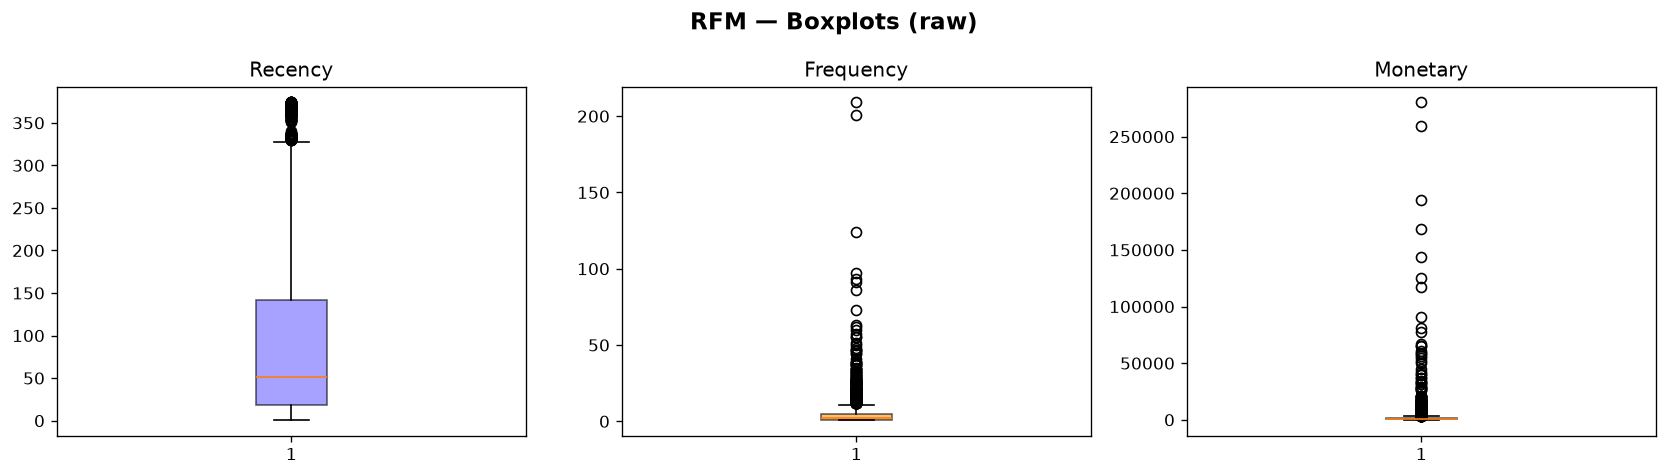

✅ Saved 01_rfm_boxplots.png


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, c in zip(axes, ["Recency", "Frequency", "Monetary"], PALETTE):
    ax.boxplot(rfm[col], patch_artist=True,
               boxprops=dict(facecolor=c, alpha=0.6))
    ax.set_title(col)
plt.suptitle("RFM — Boxplots (raw)", fontsize=14, fontweight="bold")
plt.tight_layout()
os.makedirs("../assets/screenshots", exist_ok=True)
plt.savefig("../assets/screenshots/01_rfm_boxplots.png")
plt.show()
print("✅ Saved 01_rfm_boxplots.png")

## 🔢 5. Log-Transform & Normalisation

In [6]:
print("\n🔢 Log-transform & StandardScaler…")

rfm_log = rfm[["Recency", "Frequency", "Monetary"]].copy()
rfm_log["Frequency"] = np.log1p(rfm_log["Frequency"])
rfm_log["Monetary"]  = np.log1p(rfm_log["Monetary"])

scaler   = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)


🔢 Log-transform & StandardScaler…


## 📈 6. Elbow Method

📈 Elbow method…


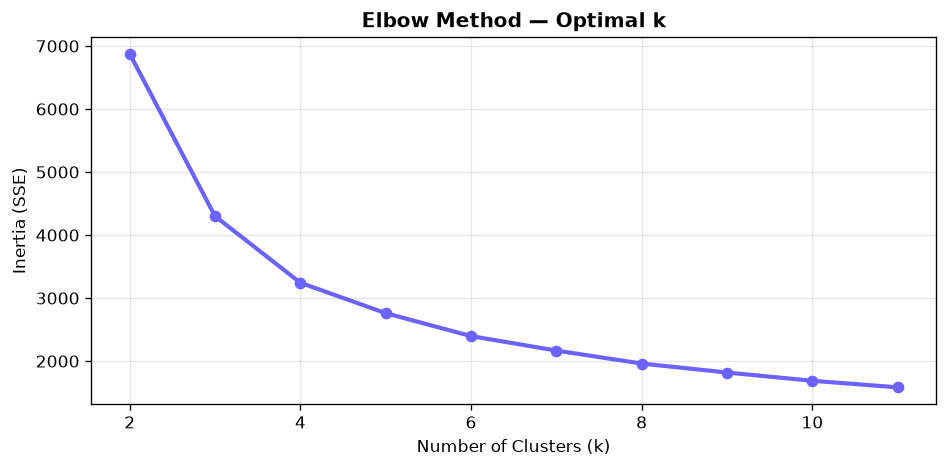

✅ Saved 02_elbow.png


In [7]:
print("📈 Elbow method…")
inertias = []
K_RANGE  = range(2, 12)

for k in K_RANGE:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    km.fit(rfm_scaled)
    inertias.append(km.inertia_)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(list(K_RANGE), inertias, "o-", color=PALETTE[0], linewidth=2.5)
ax.set_xlabel("Number of Clusters (k)")
ax.set_ylabel("Inertia (SSE)")
ax.set_title("Elbow Method — Optimal k", fontweight="bold")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../assets/screenshots/02_elbow.png")
plt.show()
print("✅ Saved 02_elbow.png")

## 📏 7. Silhouette Score

📏 Silhouette scores…


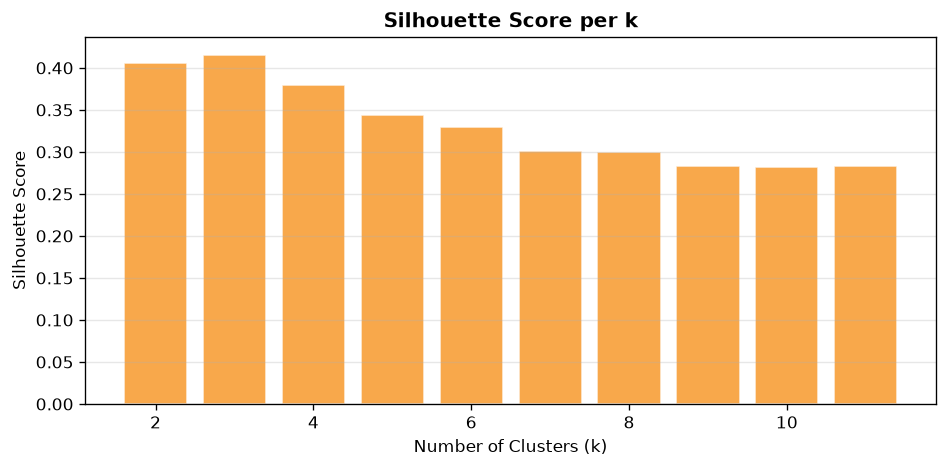

✅ Best k by silhouette = 3
🎯 Chosen k = 4


In [8]:
print("📏 Silhouette scores…")
sil_scores = []

for k in K_RANGE:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    labels = km.fit_predict(rfm_scaled)
    sil_scores.append(silhouette_score(rfm_scaled, labels))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(list(K_RANGE), sil_scores, color=PALETTE[1], alpha=0.8, edgecolor="white")
ax.set_xlabel("Number of Clusters (k)")
ax.set_ylabel("Silhouette Score")
ax.set_title("Silhouette Score per k", fontweight="bold")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("../assets/screenshots/03_silhouette.png")
plt.show()

BEST_K = list(K_RANGE)[sil_scores.index(max(sil_scores))]
print(f"✅ Best k by silhouette = {BEST_K}")

# Override if elbow is visually at 4
CHOSEN_K = 4
print(f"🎯 Chosen k = {CHOSEN_K}")

## 🤖 8. Train K-Means

In [9]:
km_final = KMeans(n_clusters=CHOSEN_K, init="k-means++", n_init=20, random_state=42)
rfm["Cluster"] = km_final.fit_predict(rfm_scaled)
print(rfm["Cluster"].value_counts())

Cluster
3    1452
0    1377
1     938
2     571
Name: count, dtype: int64

## 📋 9. Cluster Profiling & Labelling

In [10]:
cluster_summary = rfm.groupby("Cluster")[["Recency","Frequency","Monetary"]].mean().round(1)
print("\n📋 Cluster Means:\n", cluster_summary)

# Assign segment labels based on profile
#  Sort clusters: Champions = high F, high M, low R
cluster_summary["Score"] = (
    -cluster_summary["Recency"] +
     cluster_summary["Frequency"] * 10 +
     cluster_summary["Monetary"] / 100
)
rank = cluster_summary["Score"].rank(ascending=False).astype(int)
label_map = {
    rank[rank==1].index[0]: "🏆 Champions",
    rank[rank==2].index[0]: "💛 Loyal Customers",
    rank[rank==3].index[0]: "⚠️  At Risk",
    rank[rank==4].index[0]: "💤 Lost / Inactive",
}
rfm["Segment"] = rfm["Cluster"].map(label_map)
print("\n🏷️  Segment distribution:\n", rfm["Segment"].value_counts())


📋 Cluster Means:
          Recency  Frequency  Monetary
Cluster                              
0           58.0        1.5     384.2
1          259.4        1.4     385.4
2           19.8       15.8    9823.4
3           46.1        4.2    1644.3

🏷️  Segment distribution:
 Segment
💛 Loyal Customers    1452
⚠️  At Risk          1377
💤 Lost / Inactive     938
🏆 Champions           571
Name: count, dtype: int64


## 🐍 10. Snake Plot

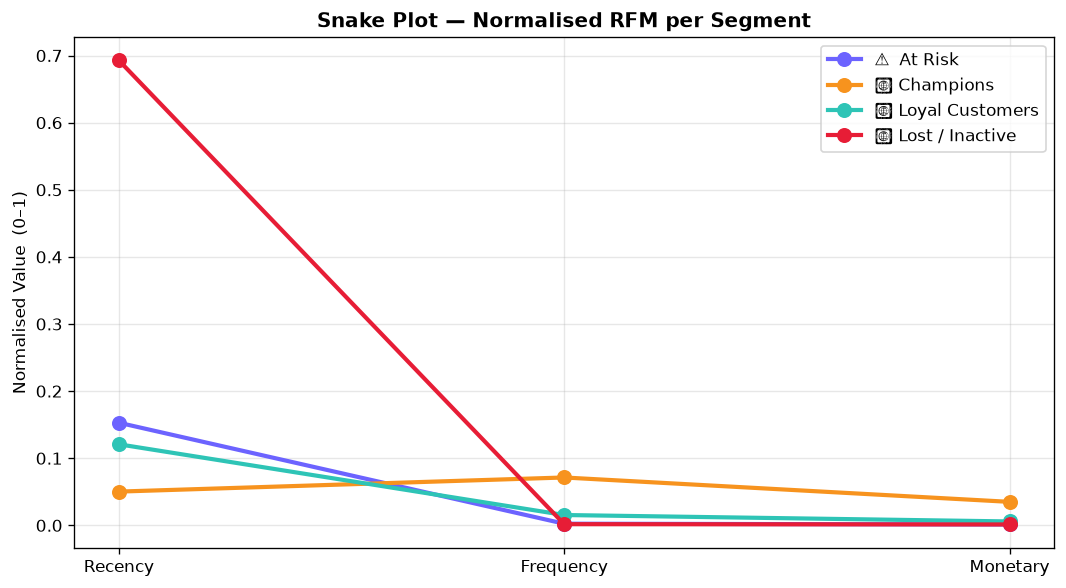

✅ Saved 04_snake_plot.png


In [11]:
rfm_norm = rfm.copy()
for col in ["Recency", "Frequency", "Monetary"]:
    rfm_norm[col] = (rfm[col] - rfm[col].min()) / (rfm[col].max() - rfm[col].min())

snake = rfm_norm.groupby("Segment")[["Recency","Frequency","Monetary"]].mean()

fig, ax = plt.subplots(figsize=(9, 5))
for i, (seg, row) in enumerate(snake.iterrows()):
    ax.plot(["Recency","Frequency","Monetary"], row.values,
            "o-", linewidth=2.5, color=PALETTE[i], label=seg, markersize=8)
ax.set_title("Snake Plot — Normalised RFM per Segment", fontweight="bold")
ax.set_ylabel("Normalised Value  (0–1)")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../assets/screenshots/04_snake_plot.png")
plt.show()
print("✅ Saved 04_snake_plot.png")

## 🌡️ 11. Heatmap

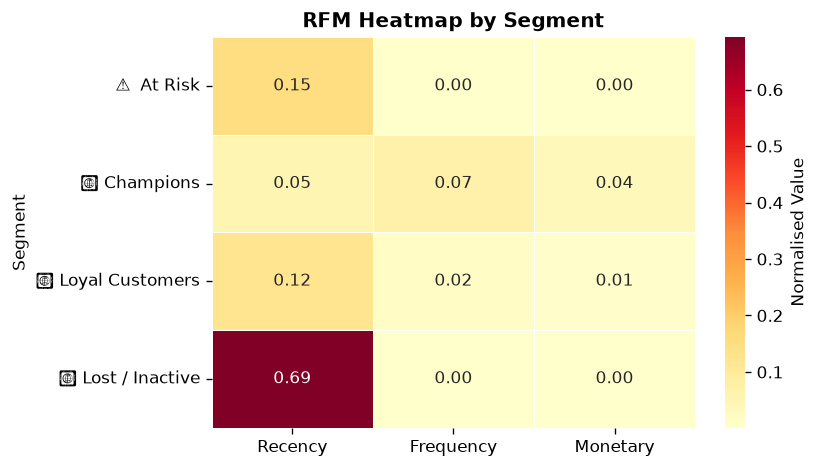

✅ Saved 05_heatmap.png


In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(snake, annot=True, fmt=".2f", cmap="YlOrRd",
            linewidths=0.5, ax=ax, cbar_kws={"label": "Normalised Value"})
ax.set_title("RFM Heatmap by Segment", fontweight="bold")
plt.tight_layout()
plt.savefig("../assets/screenshots/05_heatmap.png")
plt.show()
print("✅ Saved 05_heatmap.png")

## 🔵 12. PCA 2D Scatter

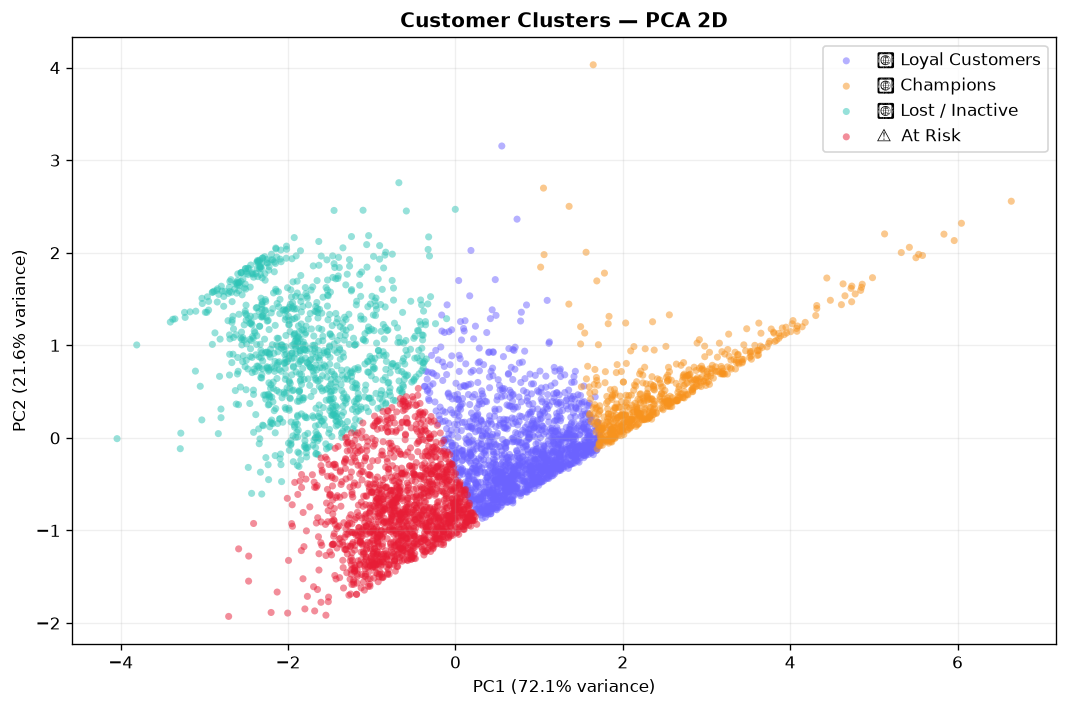

✅ Saved 06_pca_scatter.png


In [13]:
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(rfm_scaled)
rfm["PC1"] = coords[:, 0]
rfm["PC2"] = coords[:, 1]

fig, ax = plt.subplots(figsize=(9, 6))
for i, seg in enumerate(rfm["Segment"].unique()):
    sub = rfm[rfm["Segment"] == seg]
    ax.scatter(sub["PC1"], sub["PC2"], label=seg,
               color=PALETTE[i], alpha=0.5, s=18, edgecolors="none")
ax.set_title("Customer Clusters — PCA 2D", fontweight="bold")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("../assets/screenshots/06_pca_scatter.png")
plt.show()
print("✅ Saved 06_pca_scatter.png")

## 🥧 13. Segment Distribution (Pie Chart)

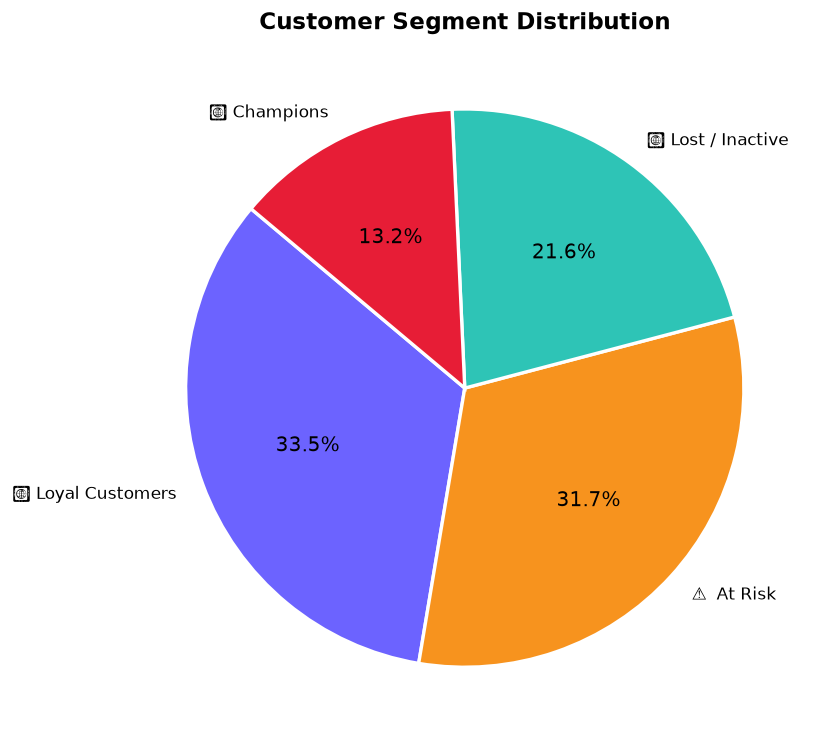

✅ Saved 07_pie_chart.png


In [14]:
counts = rfm["Segment"].value_counts()
fig, ax = plt.subplots(figsize=(7, 7))
wedges, texts, autotexts = ax.pie(
    counts, labels=counts.index, autopct="%1.1f%%",
    colors=PALETTE[:len(counts)], startangle=140,
    wedgeprops=dict(edgecolor="white", linewidth=2)
)
for t in autotexts:
    t.set_fontsize(12)
ax.set_title("Customer Segment Distribution", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.savefig("../assets/screenshots/07_pie_chart.png")
plt.show()
print("✅ Saved 07_pie_chart.png")

## 💰 14. Revenue by Segment

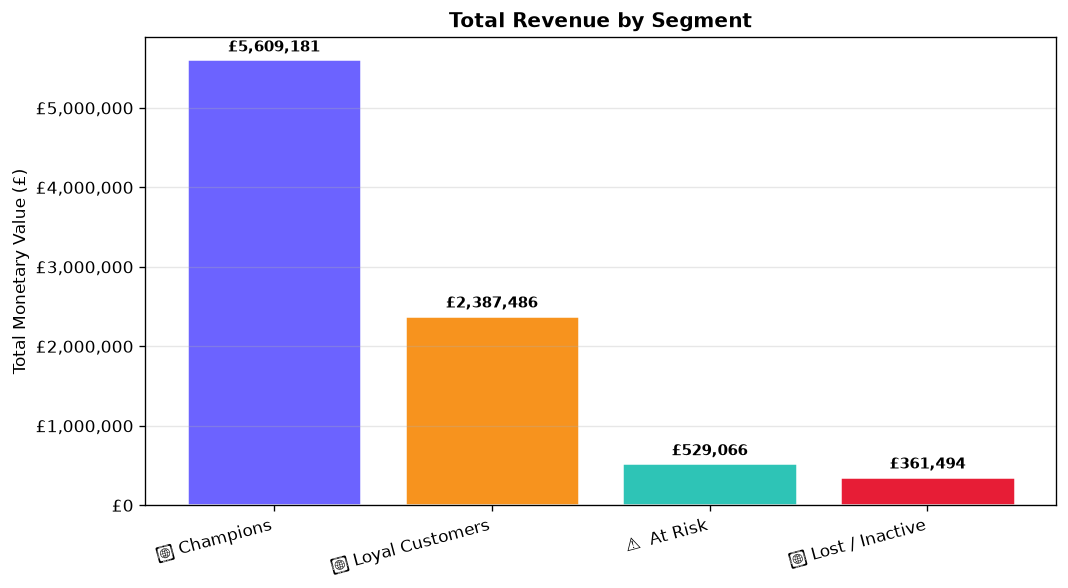

✅ Saved 08_revenue_bar.png


In [15]:
rev = rfm.groupby("Segment")["Monetary"].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(rev.index, rev.values, color=PALETTE[:len(rev)],
              edgecolor="white", linewidth=1.5)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"£{x:,.0f}"))
ax.set_title("Total Revenue by Segment", fontweight="bold")
ax.set_ylabel("Total Monetary Value (£)")
ax.grid(axis="y", alpha=0.3)
for bar, val in zip(bars, rev.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + rev.max()*0.01,
            f"£{val:,.0f}", ha="center", va="bottom", fontsize=9, fontweight="bold")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig("../assets/screenshots/08_revenue_bar.png")
plt.show()
print("✅ Saved 08_revenue_bar.png")

## 📣 15. Marketing Recommendations

In [16]:
recommendations = {
    "🏆 Champions": [
        "Reward with VIP loyalty program & exclusive offers",
        "Ask for reviews / referrals",
        "Early access to new products"
    ],
    "💛 Loyal Customers": [
        "Upsell & cross-sell complementary products",
        "Send personalised thank-you emails",
        "Offer membership / subscription deals"
    ],
    "⚠️  At Risk": [
        "Send win-back campaign: 'We miss you!' + discount",
        "Personalised product recommendations",
        "SMS/email re-engagement sequence"
    ],
    "💤 Lost / Inactive": [
        "Last-chance reactivation offer (big discount)",
        "Survey: why did they stop?",
        "Consider removing from active mailing list"
    ],
}

print("\n" + "="*55)
print("  📣  MARKETING RECOMMENDATIONS BY SEGMENT")
print("="*55)
for seg, actions in recommendations.items():
    print(f"\n{seg}")
    for a in actions:
        print(f"   → {a}")


  📣  MARKETING RECOMMENDATIONS BY SEGMENT

🏆 Champions
   → Reward with VIP loyalty program & exclusive offers
   → Ask for reviews / referrals
   → Early access to new products

💛 Loyal Customers
   → Upsell & cross-sell complementary products
   → Send personalised thank-you emails
   → Offer membership / subscription deals

⚠️  At Risk
   → Send win-back campaign: 'We miss you!' + discount
   → Personalised product recommendations
   → SMS/email re-engagement sequence

💤 Lost / Inactive
   → Last-chance reactivation offer (big discount)
   → Survey: why did they stop?
   → Consider removing from active mailing list


## 💾 16. Export Results

In [17]:
rfm.to_csv("../data/rfm_clustered.csv", index=False)
print("\n✅ rfm_clustered.csv exported.")
print("\n🎉 Done! All charts saved to assets/screenshots/")


✅ rfm_clustered.csv exported.

🎉 Done! All charts saved to assets/screenshots/
